In [42]:
from typing_extensions import TypedDict
from langgraph.graph import StateGraph, START, END
from langchain_ollama import ChatOllama

In [43]:
class subState(TypedDict):
    input_text: str
    translated_text: str
    

In [44]:
subgraph_llm = ChatOllama(model = "qwen2.5")

In [45]:
def translate_text(state: subState):
    promt = f"""
    Translate the following text into Hindi.
    Keep it natural and clear. Do not add extra content.
    
    Text:
    {state["input_text"]}""".strip()
    translate_text = subgraph_llm.invoke(promt).content
    return {"translated_text": translate_text}
    

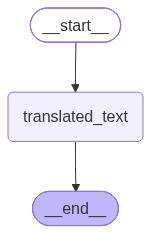

In [46]:
subgraph_builder = StateGraph(subState)

subgraph_builder.add_node("translated_text", translate_text)

subgraph_builder.add_edge(START, "translated_text")
subgraph_builder.add_edge("translated_text", END)

subgraph = subgraph_builder.compile()
subgraph


In [47]:
class ParentGraph(TypedDict):
    question:str
    answer_eng: str
    answer_hin: str
    

In [48]:
parentgraph_llm = ChatOllama(model = "qwen2.5")

In [49]:
def generate_answer(state: ParentGraph):
    answer = parentgraph_llm.invoke(f"You are a helpful assistant. Answer clearly \n\n Question:{state['question']}").content
    return {"answer_eng": answer}

In [50]:
def translate_answer(state: ParentGraph):
    result = subgraph.invoke({"input_text": state["answer_eng"]})
    return {"answer_hin": result["translated_text"]}

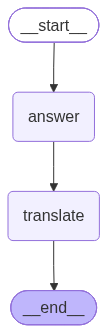

In [51]:
parent_builder = StateGraph(ParentGraph)

parent_builder.add_node("answer",generate_answer)
parent_builder.add_node("translate",translate_answer)

parent_builder.add_edge(START, "answer")
parent_builder.add_edge("answer", "translate")
parent_builder.add_edge("translate", END)

graph = parent_builder.compile()
graph

In [52]:
graph.invoke({"question": "What is quantum Physics?"})

{'question': 'What is quantum Physics?',
 'answer_eng': "Quantum physics, also known as quantum mechanics or quantum theory, is a fundamental branch of physics that studies the physical properties of nature at the scale of atoms and subatomic particles. It describes the behavior of particles at the smallest scales and provides a mathematical framework for understanding and predicting phenomena that are impossible to explain using classical physics.\n\nKey aspects of quantum physics include:\n\n1. **Quantization of Energy**: Unlike classical physics, which allows for continuous values of energy, quantum physics introduces the concept that energy is quantized—meaning it can only take on certain discrete values.\n\n2. **Wave-Particle Duality**: Quantum physics suggests that all matter and energy exhibit both particle-like and wave-like behavior. For example, light can behave as both a particle (photon) and a wave.\n\n3. **Heisenberg Uncertainty Principle**: This principle, formulated by W